# ЛР 4. AutoML. Вариант 3 — Steel Plates Faults
## Часть 1. EDA

Датасет: OpenML 40982 (`steel-plates-fault`), дефекты стальных листов, 7 классов.
Признаки в OpenML названы V1…V27, названия взяли с UCI (порядок совпадает, проверили по первой строке).

Окружение: `lab4_base`. Перед запуском один раз выполнить `python prepare_data.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif

from common import load_data, get_train_test, TARGET

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
df = load_data()
print(df.shape)
df.head()

(1941, 28)


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,target
0,42.0,50.0,270900.0,270944.0,267.0,17.0,44.0,24220.0,76.0,108.0,1687.0,1.0,0.0,80.0,0.0498,0.2415,0.1818,0.0047,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,Pastry
1,645.0,651.0,2538079.0,2538108.0,108.0,10.0,30.0,11397.0,84.0,123.0,1687.0,1.0,0.0,80.0,0.7647,0.3793,0.2069,0.0036,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,Pastry
2,829.0,835.0,1553913.0,1553931.0,71.0,8.0,19.0,7972.0,99.0,125.0,1623.0,1.0,0.0,100.0,0.9710,0.3426,0.3333,0.0037,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,Pastry
3,853.0,860.0,369370.0,369415.0,176.0,13.0,45.0,18996.0,99.0,126.0,1353.0,0.0,1.0,290.0,0.7287,0.4413,0.1556,0.0052,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,Pastry
4,1289.0,1306.0,498078.0,498335.0,2409.0,60.0,260.0,246930.0,37.0,126.0,1353.0,0.0,1.0,185.0,0.0695,0.4486,0.0662,0.0126,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,Pastry


### 1. Типы признаков, пропуски, дубликаты

In [2]:
print(df.dtypes.value_counts())
print("пропусков всего:", df.isna().sum().sum())
print("полных дубликатов строк:", df.duplicated().sum())
print("дубликатов по признакам (без таргета):", df.drop(columns=[TARGET]).duplicated().sum())
print()
print("число уникальных значений у признаков с малым числом значений:")
nun = df.drop(columns=[TARGET]).nunique().sort_values()
print(nun.head(6))

float64    27
str         1
Name: count, dtype: int64
пропусков всего: 0
полных дубликатов строк: 0
дубликатов по признакам (без таргета): 0

число уникальных значений у признаков с малым числом значений:
TypeOfSteel_A400           2
TypeOfSteel_A300           2
Outside_Global_Index       3
Steel_Plate_Thickness     24
Length_of_Conveyer        84
Maximum_of_Luminosity    100
dtype: int64


### 2. Баланс классов

              кол-во  доля, %
target                       
Other_Faults     673     34.7
Bumps            402     20.7
K_Scratch        391     20.1
Z_Scratch        190      9.8
Pastry           158      8.1
Stains            72      3.7
Dirtiness         55      2.8

в отложенном тесте (20%):
target
Other_Faults    135
Bumps            81
K_Scratch        78
Z_Scratch        38
Pastry           32
Stains           14
Dirtiness        11
Name: count, dtype: int64


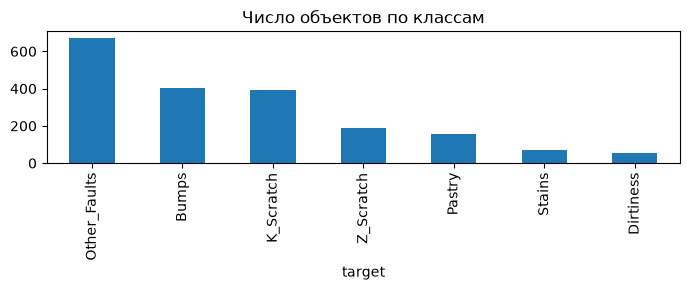

In [3]:
vc = df[TARGET].value_counts()
print(pd.DataFrame({"кол-во": vc, "доля, %": (vc / len(df) * 100).round(1)}))

train, test = get_train_test("main")
print()
print("в отложенном тесте (20%):")
print(test[TARGET].value_counts())

vc.plot(kind="bar", figsize=(7, 3), title="Число объектов по классам")
plt.tight_layout(); plt.savefig("results/plots/eda_classes.png", dpi=120); plt.show()

Основная метрика — **F1-macro**: все типы дефектов для заказчика одинаково важны, редкий дефект (Dirtiness, Stains) нельзя «потерять» ради точности на частых классах. Accuracy на таком дисбалансе завышает впечатление (константа уже даёт ~35%).

**Вывод:** классы заметно несбалансированы: самый частый Other_Faults — 34.7 %, самый редкий Dirtiness — 2.8 % (в 12 раз реже). В тесте Dirtiness всего 11 объектов, Stains — 14, поэтому одна ошибка на таком классе сдвигает его F1 на несколько пунктов, и F1-macro будет «шумной». Отсюда: стратификация при разбиении обязательна, а сравнивать системы нужно с учётом разброса по сидам, а не по одному запуску.

### 3. Порядок строк в файле

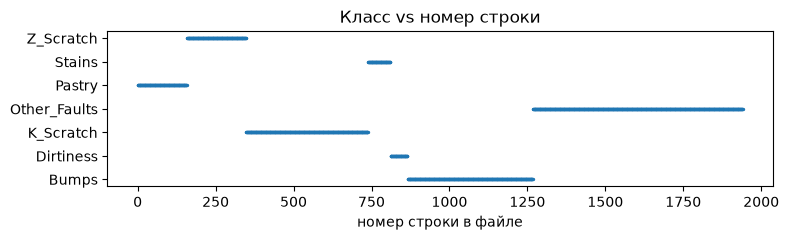

In [4]:
codes = df[TARGET].astype("category").cat.codes
plt.figure(figsize=(8, 2.5))
plt.scatter(np.arange(len(df)), codes, s=2)
plt.yticks(range(7), df[TARGET].astype("category").cat.categories)
plt.xlabel("номер строки в файле"); plt.title("Класс vs номер строки")
plt.tight_layout(); plt.savefig("results/plots/eda_row_order.png", dpi=120); plt.show()

Строки в исходном файле **отсортированы по классу**. Если где-то разбить данные без перемешивания (KFold без shuffle, «первые 80%»), в тест попадут почти одни Other_Faults. Поэтому в `common.py` train и test берутся по перемешанным индексам из `train_test_split(shuffle=True, stratify=...)`, и в AutoML данные подаются уже перемешанными.

**Вывод:** без перемешивания любая валидация была бы некорректной (train и test состояли бы из разных классов). У нас все разбиения сделаны с `shuffle=True` и стратификацией, а AutoML-системы получают уже перемешанный train, поэтому их внутренняя кросс-валидация тоже корректна.

### 4. Описательные статистики и масштабы признаков

In [5]:
df.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
X_Minimum,5.711360e+02,5.206907e+02,0.0000,1.705000e+03
X_Maximum,6.179645e+02,4.976274e+02,4.0000,1.713000e+03
Y_Minimum,1.650685e+06,1.774578e+06,6712.0000,1.298766e+07
Y_Maximum,1.650739e+06,1.774590e+06,6724.0000,1.298769e+07
Pixels_Areas,1.893878e+03,5.168460e+03,2.0000,1.526550e+05
X_Perimeter,1.118552e+02,3.012092e+02,2.0000,1.044900e+04
Y_Perimeter,8.296600e+01,4.264829e+02,1.0000,1.815200e+04
Sum_of_Luminosity,2.063121e+05,5.122936e+05,250.0000,1.159141e+07
Minimum_of_Luminosity,8.454869e+01,3.213428e+01,0.0000,2.030000e+02
Maximum_of_Luminosity,1.301937e+02,1.869099e+01,37.0000,2.530000e+02


Масштабы очень разные (Y_Minimum до ~1.3·10⁷, индексы от 0 до 1), для логистической регрессии нужен StandardScaler.

### 5. Взаимосвязи признаков

TypeOfSteel_A300 + TypeOfSteel_A400: {1.0: 1941}

пары признаков с |корреляцией| > 0.9:
TypeOfSteel_A300  TypeOfSteel_A400    -1.000000
Y_Minimum         Y_Maximum            1.000000
X_Minimum         X_Maximum            0.988314
Pixels_Areas      Sum_of_Luminosity    0.978952
                  X_Perimeter          0.966644
X_Perimeter       Sum_of_Luminosity    0.912956
                  Y_Perimeter          0.912436
dtype: float64


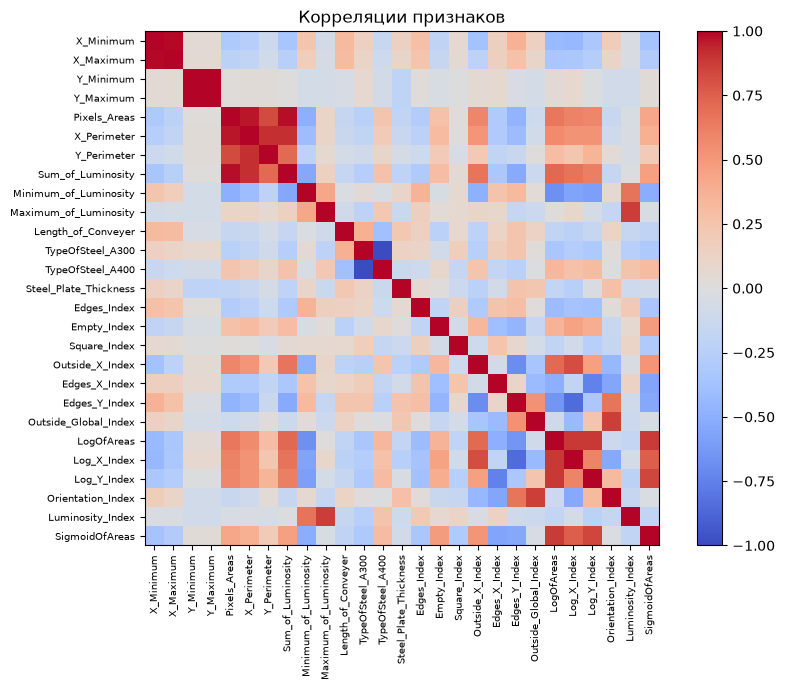

In [6]:
print("TypeOfSteel_A300 + TypeOfSteel_A400:", (df.TypeOfSteel_A300 + df.TypeOfSteel_A400).value_counts().to_dict())

corr = df.drop(columns=[TARGET]).corr()
mask = np.triu(np.ones(corr.shape, dtype=bool), 1)
pairs = corr.where(mask).stack()
print()
print("пары признаков с |корреляцией| > 0.9:")
print(pairs[pairs.abs() > 0.9].sort_values(key=abs, ascending=False))

plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
plt.yticks(range(len(corr)), corr.columns, fontsize=7)
plt.title("Корреляции признаков")
plt.tight_layout(); plt.savefig("results/plots/eda_corr.png", dpi=120); plt.show()

TypeOfSteel_A300 и TypeOfSteel_A400 — один и тот же признак, закодированный дважды (в сумме всегда 1). Y_Minimum/Y_Maximum, X_Minimum/X_Maximum, площадь/яркость/периметр почти дублируют друг друга. Для деревьев это не страшно, для линейной модели — мультиколлинеарность (L2-регуляризация в LogisticRegression её сглаживает).

**Вывод:** независимых признаков меньше, чем 27: TypeOfSteel_A400 полностью избыточен (= 1 − A300), Y_Maximum ≈ Y_Minimum, X_Maximum ≈ X_Minimum, площадь, яркость и периметры сильно связаны. Удалять признаки не стали: бустинги и AutoML к дублям устойчивы, а логистическую регрессию (B1) спасает L2-регуляризация. Но при чтении важности признаков (п. 10 анализа) нужно помнить, что у пары дублей важность делится между ними.

### 6. Связь признаков с целевой переменной

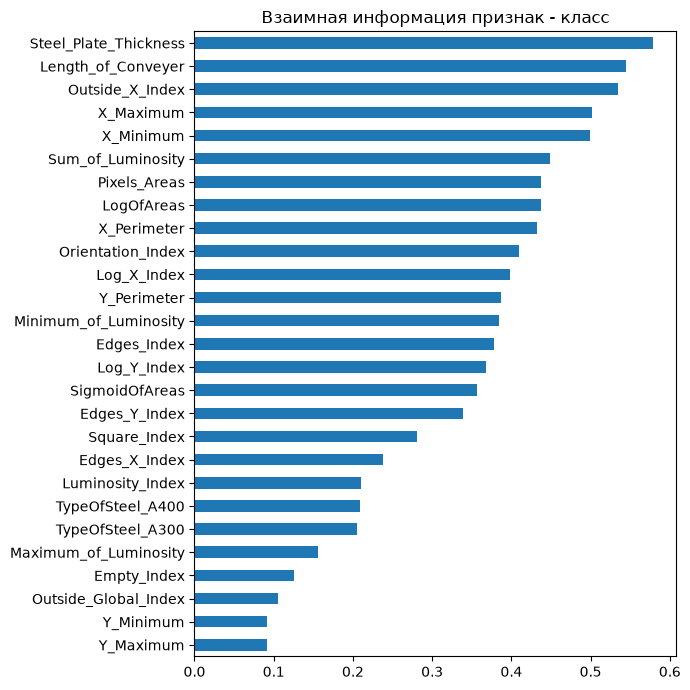

Steel_Plate_Thickness    0.579277
Length_of_Conveyer       0.545271
Outside_X_Index          0.534693
X_Maximum                0.501470
X_Minimum                0.499411
Sum_of_Luminosity        0.448648
Pixels_Areas             0.437901
LogOfAreas               0.437804
X_Perimeter              0.431930
Orientation_Index        0.410024
dtype: float64

In [7]:
mi = mutual_info_classif(df.drop(columns=[TARGET]), df[TARGET], random_state=0)
mi = pd.Series(mi, index=df.columns[:-1]).sort_values(ascending=False)
mi.plot(kind="barh", figsize=(7, 7), title="Взаимная информация признак - класс")
plt.gca().invert_yaxis()
plt.tight_layout(); plt.savefig("results/plots/eda_mutual_info.png", dpi=120); plt.show()
mi.head(10)

Таргет категориальный (7 классов), поэтому вместо корреляции Пирсона — взаимная информация.

### 7. Известен ли признак в момент прогноза?

Прогноз делается, когда система контроля нашла дефект на листе и нужно определить его тип.

| Группа признаков | Признаки | Известен в момент прогноза? |
|---|---|---|
| Геометрия дефекта | X/Y_Minimum, X/Y_Maximum, Pixels_Areas, X/Y_Perimeter | да — считается по изображению дефекта |
| Яркость | Sum/Minimum/Maximum_of_Luminosity, Luminosity_Index | да — по изображению |
| Производные индексы | Edges_Index, Empty_Index, Square_Index, Outside_X_Index, Edges_X/Y_Index, Outside_Global_Index, LogOfAreas, Log_X/Y_Index, Orientation_Index, SigmoidOfAreas | да — формулы от геометрии |
| Параметры листа | Length_of_Conveyer, TypeOfSteel_A300/A400, Steel_Plate_Thickness | да — известны до контроля |

Признаков «из будущего» (как в вариантах AI4I или Bank Marketing) тут нет. Но параметры листа вызывают другой вопрос — следующий пункт.

### 8. «Изюминка»: несколько дефектов с одного листа

Признаки Length_of_Conveyer, Steel_Plate_Thickness и TypeOfSteel описывают **лист**, а не дефект. Если их сочетание повторяется, это, скорее всего, один и тот же лист (или партия). Проверим, сколько таких «псевдолистов» и насколько однородны дефекты внутри них.

In [8]:
plate_cols = ["Length_of_Conveyer", "Steel_Plate_Thickness", "TypeOfSteel_A300"]
plate_id = df[plate_cols].astype(str).agg("_".join, axis=1)
g = df.groupby(plate_id)[TARGET]
sizes = g.size()
purity = g.agg(lambda s: s.value_counts(normalize=True).iloc[0])
print("псевдолистов:", plate_id.nunique())
print("дефектов на лист: медиана", sizes.median(), ", максимум", sizes.max())
print("доля самого частого класса внутри листа (взвешенно):", round((purity * sizes).sum() / sizes.sum(), 3))
print("доля самого частого класса во всём датасете:", round(df[TARGET].value_counts(normalize=True).iloc[0], 3))

псевдолистов: 239
дефектов на лист: медиана 3.0 , максимум 133
доля самого частого класса внутри листа (взвешенно): 0.766
доля самого частого класса во всём датасете: 0.347


Если внутри листа дефекты в основном одного типа, то при случайном разбиении дефекты одного листа попадают и в train, и в test, и модель может «узнавать лист», а не тип дефекта. Проверим на CatBoost с параметрами по умолчанию: обычная стратифицированная кросс-валидация против кросс-валидации, где один лист целиком либо в train, либо в test (`StratifiedGroupKFold`). Считаем только на train-части, тест не трогаем.

In [9]:
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_score

train_df = df.loc[pd.read_csv("data/train_idx.csv")["idx"]]
X_tr, y_tr = train_df.drop(columns=[TARGET]), train_df[TARGET]
groups_tr = plate_id.loc[train_df.index]

model = CatBoostClassifier(iterations=500, random_seed=0, thread_count=4, verbose=0)
cv_random = cross_val_score(model, X_tr, y_tr, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="f1_macro")
cv_group = cross_val_score(model, X_tr, y_tr, cv=StratifiedGroupKFold(5, shuffle=True, random_state=0),
                           groups=groups_tr, scoring="f1_macro")
print(f"случайные фолды:        F1-macro = {cv_random.mean():.3f} ± {cv_random.std():.3f}")
print(f"фолды по псевдолистам:  F1-macro = {cv_group.mean():.3f} ± {cv_group.std():.3f}")

случайные фолды:        F1-macro = 0.805 ± 0.021
фолды по псевдолистам:  F1-macro = 0.766 ± 0.030


Основной протокол лабы оставляем как в задании (случайные 20% со стратификацией), но эту особенность обязательно упомянуть в отчёте в разделе «Ограничения» и в записке заказчику: AutoML её сам не заметит.

**Вывод:** разрыв есть: 0.805 при случайных фолдах против 0.766 при фолдах по псевдолистам, то есть около 0.04 F1-macro, что больше стандартного отклонения по фолдам (0.02–0.03). Дефекты одного «листа» в основном однотипны (доля самого частого класса внутри листа 0.77 против 0.35 по датасету), и при случайном разбиении модель частично «узнаёт лист» по его параметрам. Значит, все числа на нашем тесте — оценка сверху: на новом листе, которого не было в обучении, стоит ожидать F1-macro примерно на 0.04 ниже. Сравнение систем между собой это не ломает (условия у всех одинаковые), но заказчику нужно называть осторожную цифру.

### 9. Метрика и схема валидации (итог EDA)

- Основная метрика: F1-macro; дополнительно accuracy и матрица ошибок.
- Тест: 20% со стратификацией, `random_state=42`, индексы сохранены в `data/test_idx.csv` один раз (`prepare_data.py`). Все системы учатся только на оставшихся 80%.
- Внутри train каждая система валидируется сама (LightAutoML — 5 фолдов, FEDOT — 5 фолдов (cv_folds=5 по умолчанию), AutoGluon — holdout 20% (при medium_quality без бэггинга), B3 — 3 фолда в Optuna).